# Predicting cropland flood exposure from rainfall (Aweil East + South)
**Objective:** an interpretable rainfall predictor that, by the end of the rainy season (31 August), estimates flood severity in Aweil East and Aweil South, evaluated out of sample to quantify how much cropland is exposed.

`aweil_analysis.ipynb` tested rainfall against a *detection-based* flood severity index. Here the target is **cropland exposure** itself, computed with the same method as `Cropland_analysis.ipynb`:
- **Target per season:** % of cropland (crop-weighted, ASAP mask) flooded at least once in the **worst month of Sep-Dec**, Aweil East + South combined.
- **Predictors (known on 31 Aug):** local ERA5 rainfall over Aweil East + South, Jun-Aug and Jul-Aug totals.
- **Model:** linear, `log(exposure) ~ year + rain` (the year term removes the trend / sensor drift inside each fold). Compared with a **trend-only** baseline `log(exposure) ~ year`.
- **Evaluation:** leave-one-season-out (LOO), seasons 2003-2024 (2000-02 have very low flood-data coverage; 2025 kept aside as a final check).

This notebook is self-contained: it only needs `raw_data/`.

In [10]:
# Setup
import sys, warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray as rxr
import xarray as xr
from scipy import stats

warnings.filterwarnings("ignore")
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "raw_data").exists())
sys.path.insert(0, str(REPO / "processing_data"))
from loading import load_flood_masks

pd.set_option("display.width", 200, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110})

a2 = gpd.read_file(REPO / "raw_data" / "Administrative boundaries" / "ssd_admin2.geojson")
ES = ["Aweil East", "Aweil South"]
es = a2[a2.adm2_name.isin(ES)]
es_geom = es.union_all()
minx, miny, maxx, maxy = es.total_bounds

SEASONS = np.arange(2003, 2025)   # evaluation seasons
TARGET_MONTHS = [9, 10, 11, 12]   # flood window after the 31 Aug decision date

## 1. Cropland exposure per season (same method as `Cropland_analysis.ipynb`, sections 2-3)

In [11]:
# Crop mask clipped to Aweil East + South; pixel area in km2
crop = rxr.open_rasterio(REPO / "raw_data" / "farmland" / "asap_mask_crop_v04.tif").squeeze("band", drop=True)
crop = crop.rio.clip_box(minx, miny, maxx, maxy)
crop = crop.where(crop <= 100).astype("float32").rio.clip([es_geom], es.crs, drop=False)
res_c = abs(crop.rio.resolution()[0])
pix_km2 = (res_c * 111.32) ** 2 * np.cos(np.deg2rad(crop.y.values))[:, None] * np.ones(crop.shape)
crop_km2 = ((crop / 100).fillna(0) * pix_km2).values          # crop-weighted km2 per pixel
whole_km2 = ((crop > 0) * pix_km2).values                     # full pixel if any crop
print(f"cropland: crop-weighted {crop_km2.sum() * 100:,.0f} ha, whole pixels {whole_km2.sum() * 100:,.0f} ha")

# Flood-pixel grid -> crop pixels (partial-pixel share = flooded / all flood pixels inside the crop pixel)
RES_F = 10 / 4800
x_edge, y_edge = float(crop.x[0]) - res_c / 2, float(crop.y[0]) + res_c / 2
n_rows, n_cols = crop.shape


def to_crop_cell(lon, lat):
    col = np.floor((np.asarray(lon) - x_edge) / res_c).astype(int)
    row = np.floor((y_edge - np.asarray(lat)) / res_c).astype(int)
    out = (col < 0) | (col >= n_cols) | (row < 0) | (row >= n_rows)
    return np.where(out, -1, row), np.where(out, -1, col)


f_lon = np.arange(np.floor(minx / RES_F) - 1, np.ceil(maxx / RES_F) + 2) * RES_F + RES_F / 2
f_lat = np.arange(np.floor(miny / RES_F) - 1, np.ceil(maxy / RES_F) + 2) * RES_F + RES_F / 2
LON, LAT = np.meshgrid(f_lon, f_lat)
r, c = to_crop_cell(LON.ravel(), LAT.ravel())
n_total = np.zeros(crop.shape)
np.add.at(n_total, (r[r >= 0], c[r >= 0]), 1)

fl = load_flood_masks(np.arange(2000, 2026), bbox={"lon_min": minx, "lon_max": maxx, "lat_min": miny, "lat_max": maxy})
fl["month"] = pd.to_datetime(fl["date"].astype(str)).dt.to_period("M")
fl = fl.drop_duplicates(["month", "lat", "lon"])
fl["row"], fl["col"] = to_crop_cell(fl.lon.values, fl.lat.values)
fl = fl[fl.row >= 0]
fc = fl.groupby(["month", "row", "col"]).size().rename("n").reset_index()
fc["share"] = np.minimum(fc.n / n_total[fc.row, fc.col], 1)

all_months = pd.period_range("2000-01", "2025-12", freq="M")
fc["crop_km2"] = fc.share * crop_km2[fc.row, fc.col]
fc["whole_km2"] = fc.share * whole_km2[fc.row, fc.col]
monthly = fc.groupby("month")[["crop_km2", "whole_km2"]].sum().reindex(all_months, fill_value=0)
monthly["pct"] = 100 * monthly.crop_km2 / crop_km2.sum()

# Season target: worst month of Sep-Dec
m = monthly[monthly.index.month.isin(TARGET_MONTHS)]
season = pd.DataFrame({
    "exposure_pct": m.pct.groupby(m.index.year).max(),
    "exposed_ha_lower": (m.crop_km2 * 100).groupby(m.index.year).max(),
    "exposed_ha_upper": (m.whole_km2 * 100).groupby(m.index.year).max(),
})
season.round(2).loc[2003:2025]

cropland: crop-weighted 22,613 ha, whole pixels 212,924 ha


,exposure_pct,exposed_ha_lower,exposed_ha_upper
2003,0.21,48.46,919.07
2004,0.00,1.04,18.29
2005,0.17,37.62,727.33
2006,0.14,32.31,624.19
2007,0.55,124.11,1958.76
2008,6.12,1384.59,16058.02
2009,0.03,5.73,174.85
2010,1.58,356.51,5362.47
2011,0.00,1.02,58.96
2012,0.05,10.44,299.57


## 2. Rainfall known on 31 August (ERA5, Aweil East + South)

In [12]:
# ERA5 cells whose 0.25 deg box touches Aweil East + South; daily rain in mm, averaged over those cells
from shapely.geometry import box

rain_daily = []
for y in range(2000, 2026):
    ds = xr.open_dataset(REPO / "raw_data" / "rainfall and runoff" / f"ERA5_{y}.nc")["tp"]
    ds = ds.sel(latitude=slice(maxy + 0.25, miny - 0.25), longitude=slice(minx - 0.25, maxx + 0.25))
    if not rain_daily:   # pick the cells once
        cells = [(la, lo) for la in ds.latitude.values for lo in ds.longitude.values
                 if box(lo - 0.125, la - 0.125, lo + 0.125, la + 0.125).intersects(es_geom)]
        lat_sel = xr.DataArray([la for la, _ in cells], dims="cell")
        lon_sel = xr.DataArray([lo for _, lo in cells], dims="cell")
        print(f"ERA5 cells touching Aweil East + South: {len(cells)}")
    d = ds.sel(latitude=lat_sel, longitude=lon_sel).mean("cell").resample(valid_time="1D").sum() * 1000
    rain_daily.append(d.to_series())
rain_daily = pd.concat(rain_daily)
rain_m = rain_daily.groupby([rain_daily.index.year, rain_daily.index.month]).sum().unstack()

feat = pd.DataFrame({
    "Jun-Aug": rain_m[[6, 7, 8]].sum(axis=1),
    "Jul-Aug": rain_m[[7, 8]].sum(axis=1),
    "annual (hindsight)": rain_m.sum(axis=1),
})
feat.index.name = "year"
print("mean Jun-Aug rain:", round(feat["Jun-Aug"].loc[2003:2024].mean()), "mm")
df = season.join(feat).loc[2003:2025]
df.round(1)

ERA5 cells touching Aweil East + South: 19
mean Jun-Aug rain: 439 mm


,exposure_pct,exposed_ha_lower,exposed_ha_upper,Jun-Aug,Jul-Aug,annual (hindsight)
2003,0.2,48.5,919.1,609.4,456.9,959.6
2004,0.0,1.0,18.3,452.1,322.7,803.0
2005,0.2,37.6,727.3,517.6,362.4,920.3
2006,0.1,32.3,624.2,537.0,394.4,918.5
2007,0.5,124.1,1958.8,544.9,419.7,823.9
2008,6.1,1384.6,16058.0,480.1,386.3,771.3
2009,0.0,5.7,174.9,445.9,334.6,728.7
2010,1.6,356.5,5362.5,487.9,387.7,886.7
2011,0.0,1.0,59.0,379.5,301.5,699.6
2012,0.0,10.4,299.6,460.1,320.1,757.7


## 3. Out-of-sample test (leave one season out)
For every season: fit on the other 21 seasons, predict the left-out one.
- **Skill vs trend-only** = 1 - SSE(model) / SSE(trend-only), on log exposure. > 0 means rainfall improves on the trend alone.
- **Honest selection:** the rain window (Jun-Aug or Jul-Aug) is chosen *inside* each fold, so picking the best window does not leak into the score.
- **Permutation test:** shuffle rainfall between seasons 2,000 times to see how often chance gives the same skill.
- log uses a floor of 0.01% so near-empty seasons (e.g. 2023) do not dominate.

In [13]:
FLOOR = 0.01  # % of cropland
d = df.loc[SEASONS].copy()
d["y"] = np.log(np.maximum(d.exposure_pct, FLOOR))
years = d.index.values.astype(float)


def fit_predict(X_tr, y_tr, X_te):
    A = np.column_stack([np.ones(len(X_tr)), X_tr])
    beta, *_ = np.linalg.lstsq(A, y_tr, rcond=None)
    return np.column_stack([np.ones(len(X_te)), X_te]) @ beta


def loo(y, X):
    pred = np.empty(len(y))
    for i in range(len(y)):
        tr = np.arange(len(y)) != i
        pred[i] = fit_predict(X[tr], y[tr], X[i:i + 1])[0]
    return pred


def loo_selected(y, rains, yrs):
    """Choose the rain window inside each fold by in-sample fit, then predict the left-out season."""
    pred, picked = np.empty(len(y)), []
    for i in range(len(y)):
        tr = np.arange(len(y)) != i
        best = min(rains, key=lambda k: np.sum((y[tr] - fit_predict(np.column_stack([yrs[tr], rains[k][tr]]), y[tr],
                                                                np.column_stack([yrs[tr], rains[k][tr]]))) ** 2))
        picked.append(best)
        pred[i] = fit_predict(np.column_stack([yrs[tr], rains[best][tr]]), y[tr],
                              np.column_stack([yrs[i:i + 1], rains[best][i:i + 1]]))[0]
    return pred, picked


y = d.y.values
pred_trend = loo(y, years[:, None])
sse_trend = np.sum((y - pred_trend) ** 2)
rains = {k: d[k].values for k in ["Jun-Aug", "Jul-Aug"]}

rows, preds = {}, {"trend only": pred_trend}
for k in ["Jun-Aug", "Jul-Aug", "annual (hindsight)"]:
    p = loo(y, np.column_stack([years, d[k].values]))
    preds[k] = p
    rows[f"year + {k}"] = 1 - np.sum((y - p) ** 2) / sse_trend
p_sel, picked = loo_selected(y, rains, years)
preds["selected in-fold"] = p_sel
rows["year + window selected in-fold (honest)"] = 1 - np.sum((y - p_sel) ** 2) / sse_trend

# Permutation test for the honest model
rng = np.random.default_rng(0)
null = []
for _ in range(2000):
    perm = rng.permutation(len(y))
    p_null, _ = loo_selected(y, {k: v[perm] for k, v in rains.items()}, years)
    null.append(1 - np.sum((y - p_null) ** 2) / sse_trend)
skill_honest = rows["year + window selected in-fold (honest)"]
p_perm = (np.sum(np.array(null) >= skill_honest) + 1) / (len(null) + 1)

res = pd.Series(rows, name="LOO skill vs trend-only").to_frame()
display(res.round(3))
print(f"windows picked in the folds: {pd.Series(picked).value_counts().to_dict()}")
print(f"honest skill {skill_honest:.3f}, permutation p = {p_perm:.3f}  (annual rain is hindsight: not known on 31 Aug)")

,LOO skill vs trend-only
year + Jun-Aug,0.444
year + Jul-Aug,0.551
year + annual (hindsight),0.236
year + window selected in-fold (honest),0.551


windows picked in the folds: {'Jul-Aug': 22}
honest skill 0.551, permutation p = 0.000  (annual rain is hindsight: not known on 31 Aug)


In [14]:
# Interpretable effect size (full-sample fit, Jun-Aug): how exposure scales with rain
X = np.column_stack([np.ones(len(y)), years, d["Jun-Aug"].values])
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ beta
dof = len(y) - X.shape[1]
se = np.sqrt(np.diag(np.sum(resid ** 2) / dof * np.linalg.inv(X.T @ X)))
b, s = beta[2] * 100, se[2] * 100
tcrit = stats.t.ppf(0.975, dof)
p_b = 2 * stats.t.sf(abs(beta[2] / se[2]), dof)
r2 = 1 - np.sum(resid ** 2) / np.sum((y - y.mean()) ** 2)
print(f"+100 mm Jun-Aug rain -> cropland exposure x{np.exp(b):.1f} "
      f"(95% CI x{np.exp(b - tcrit * s):.1f}-x{np.exp(b + tcrit * s):.1f}, p = {p_b:.3f}), in-sample R2 = {r2:.2f}")

# Robustness: without the 2023 data gap
keep = d.index != 2023
p_t = loo(y[keep], years[keep][:, None])
p_r = loo(y[keep], np.column_stack([years[keep], d["Jun-Aug"].values[keep]]))
print(f"without 2023: LOO skill (year + Jun-Aug) vs trend-only = {1 - np.sum((y[keep] - p_r) ** 2) / np.sum((y[keep] - p_t) ** 2):.3f}")

+100 mm Jun-Aug rain -> cropland exposure x10.5 (95% CI x3.2-x34.2, p = 0.001), in-sample R2 = 0.49
without 2023: LOO skill (year + Jun-Aug) vs trend-only = 0.378


## 4. What does the predictor say about exposed cropland?

In [15]:
# Log-linear predictions can overshoot far beyond anything observed (e.g. 2022, the wettest Jul-Aug on record).
# Cap each out-of-sample prediction at the highest exposure seen in its training seasons.
pred_pct = np.exp(preds["selected in-fold"])
cap = np.array([d.exposure_pct.drop(yr).max() for yr in d.index])
capped = pred_pct > cap
pred_pct = np.minimum(pred_pct, cap)
print("predictions capped at the training maximum:", list(d.index[capped]))

# Out-of-sample predictions back in % of cropland and hectares (crop-weighted lower bound; whole-pixel upper bound)
ratio_upper = (d.exposed_ha_upper / d.exposed_ha_lower.replace(0, np.nan)).median()  # typical upper/lower ratio
out = pd.DataFrame({
    "observed %": d.exposure_pct,
    "predicted % (LOO, honest)": pred_pct,
    "trend-only % (LOO)": np.exp(pred_trend),
    "observed ha (lower-upper)": [f"{lo:,.0f}-{up:,.0f}" for lo, up in zip(d.exposed_ha_lower, d.exposed_ha_upper)],
})
cropland_ha = crop_km2.sum() * 100
out["predicted ha (lower-upper)"] = [f"{p / 100 * cropland_ha:,.0f}-{p / 100 * cropland_ha * ratio_upper:,.0f}"
                                     for p in out["predicted % (LOO, honest)"]]
display(out.round(2))

# Ranking skill: does the predictor put the high-exposure seasons on top?
rho, p_rho = stats.spearmanr(d.exposure_pct, out["predicted % (LOO, honest)"])
print(f"Spearman rank correlation, observed vs LOO-predicted exposure: rho = {rho:.2f} (p = {p_rho:.3f})")

# Simple operational rule known on 31 Aug: dry Jun-Aug (bottom third vs trend) -> high exposure unlikely?
an = d["Jun-Aug"] - np.polyval(np.polyfit(years, d["Jun-Aug"], 1), years)
dry = an <= np.quantile(an, 1 / 3)
high = d.exposure_pct >= np.quantile(d.exposure_pct, 2 / 3)
print(f"P(high exposure | dry Jun-Aug) = {high[dry].mean():.0%} (n={dry.sum()});  "
      f"P(high exposure | normal/wet) = {high[~dry].mean():.0%} (n={(~dry).sum()})")

predictions capped at the training maximum: [2022]


,observed %,"predicted % (LOO, honest)",trend-only % (LOO),observed ha (lower-upper),predicted ha (lower-upper)
2003,0.21,1.05,0.08,48-919,"237-4,543"
2004,0.00,0.04,0.15,1-18,9-165
2005,0.17,0.08,0.10,38-727,19-366
2006,0.14,0.25,0.11,32-624,"56-1,071"
2007,0.55,0.49,0.10,"124-1,959","110-2,112"
2008,6.12,0.18,0.09,"1,385-16,058",41-792
2009,0.03,0.09,0.15,6-175,20-376
2010,1.58,0.30,0.12,"357-5,362","67-1,292"
2011,0.00,0.05,0.17,1-59,12-226
2012,0.05,0.09,0.16,10-300,19-373


Spearman rank correlation, observed vs LOO-predicted exposure: rho = 0.74 (p = 0.000)
P(high exposure | dry Jun-Aug) = 12% (n=8);  P(high exposure | normal/wet) = 50% (n=14)


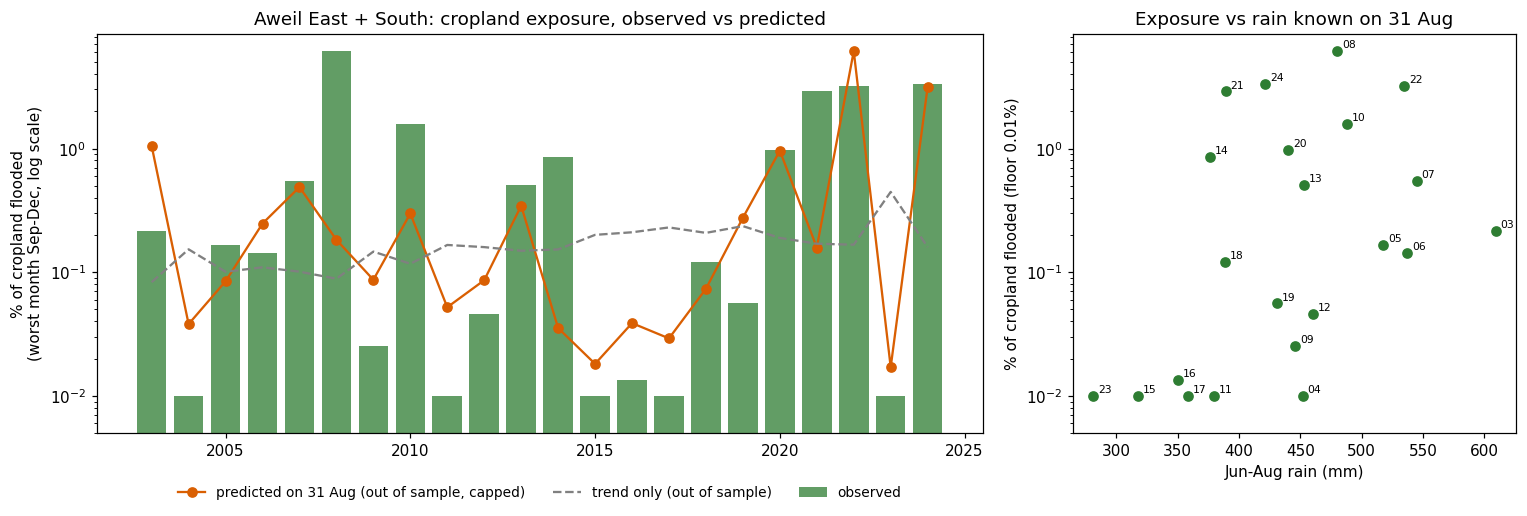

In [16]:
# Plot: observed vs out-of-sample predicted cropland exposure per season
# Values below the 0.01% floor are drawn at the floor so near-empty seasons stay visible on the log axis.
obs_plot = np.maximum(d.exposure_pct, FLOOR)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.bar(d.index, obs_plot, color="#2e7d32", alpha=0.75, label="observed")
ax.plot(d.index, out["predicted % (LOO, honest)"], "o-", color="#d95f02", label="predicted on 31 Aug (out of sample, capped)")
ax.plot(d.index, out["trend-only % (LOO)"], "--", color="grey", label="trend only (out of sample)")
ax.set_yscale("log")
ax.set_ylim(FLOOR / 2, None)
ax.set_ylabel("% of cropland flooded\n(worst month Sep-Dec, log scale)")
ax.set_title("Aweil East + South: cropland exposure, observed vs predicted")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)

ax = axes[1]
ax.scatter(d["Jun-Aug"], obs_plot, color="#2e7d32")
for yr, xv, yv in zip(d.index, d["Jun-Aug"], obs_plot):
    ax.annotate(str(yr)[2:], (xv, yv), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_yscale("log")
ax.set_ylim(FLOOR / 2, None)
ax.set_xlabel("Jun-Aug rain (mm)")
ax.set_ylabel("% of cropland flooded (floor 0.01%)")
ax.set_title("Exposure vs rain known on 31 Aug")
plt.tight_layout()
plt.show()

In [17]:
# 2025 as an unseen check: fit on 2003-2024, predict 2025 with the Jun-Aug model
full = np.column_stack([years, d["Jun-Aug"].values])
p25 = fit_predict(full, y, np.array([[2025.0, df.loc[2025, "Jun-Aug"]]]))[0]
print(f"2025: Jun-Aug rain {df.loc[2025, 'Jun-Aug']:.0f} mm -> predicted {np.exp(p25):.2f}% of cropland, "
      f"observed {df.loc[2025, 'exposure_pct']:.2f}%")

2025: Jun-Aug rain 344 mm -> predicted 0.22% of cropland, observed 0.08%


## 5. Poster figure: supporting the conclusion
Left: after a dry rainy season (Jun-Aug, bottom third relative to the trend), a season with heavy cropland flooding (top third of seasons) is rare.
Right: timeline from the 31 August decision to the October-November flood peak. Average monthly cropland flooding after dry vs normal/wet rainy seasons. Saved to `figures/poster/fig4_conclusion_rain_signal.png`.

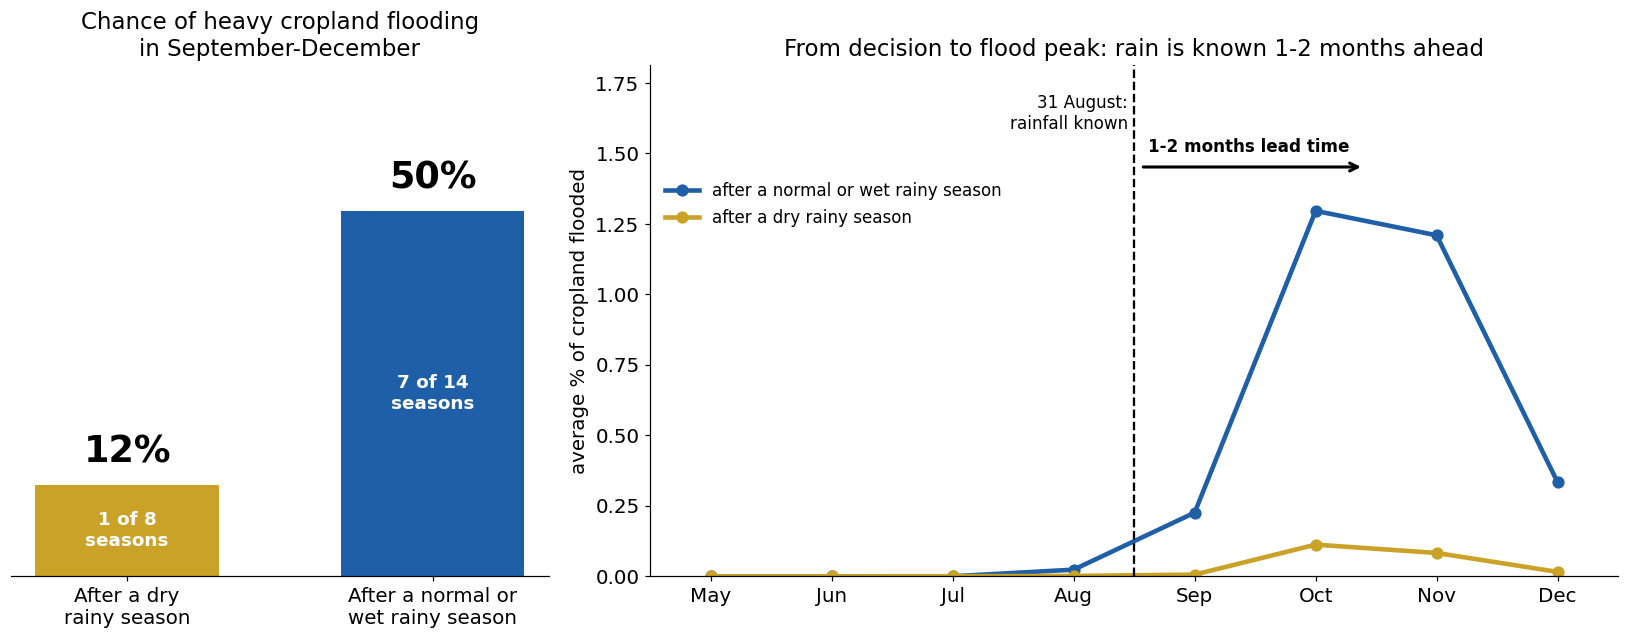

In [18]:
# Poster figure 4 - (left) chance of heavy cropland flooding after a dry vs normal/wet rainy season,
#                   (right) timeline from the 31 Aug decision to the Oct-Nov flood peak, dry vs normal/wet seasons
POSTER = REPO / "figures" / "poster"
POSTER.mkdir(parents=True, exist_ok=True)
thr = np.quantile(d.exposure_pct, 2 / 3)   # heavy flooding = top third of seasons
high = d.exposure_pct >= thr
groups = [("After a dry\nrainy season", dry), ("After a normal or\nwet rainy season", ~dry)]
COL_DRY, COL_WET, COL_OBS, COL_PRED = "#c9a227", "#1f5fa8", "#2e7d32", "#d95f02"

with plt.rc_context({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.8]})

    # Left: two bars
    for i, (label, mask) in enumerate(groups):
        share = high[mask].mean() * 100
        ax1.bar(i, share, width=0.6, color=[COL_DRY, COL_WET][i])
        ax1.text(i, share + 2, f"{share:.0f}%", ha="center", va="bottom", fontsize=24, weight="bold")
        ax1.text(i, share / 2, f"{high[mask].sum()} of {mask.sum()}\nseasons", ha="center", va="center",
                 fontsize=12, color="white", weight="bold")
    ax1.set_xticks([0, 1], [g[0] for g in groups])
    ax1.set_yticks([])
    ax1.spines["left"].set_visible(False)
    ax1.set_ylim(0, 70)
    ax1.set_title("Chance of heavy cropland flooding\nin September-December", fontsize=15)

    # Right: timeline from decision (31 Aug) to flood peak, after dry vs normal/wet rainy seasons
    mon_all = monthly.pct.copy()
    mon_df = pd.DataFrame({"pct": mon_all.values, "year": mon_all.index.year, "month": mon_all.index.month})
    mon_df = mon_df[mon_df.year.isin(d.index)]
    mon_df["dry"] = mon_df.year.map(dry)
    cyc_dry = mon_df[mon_df.dry].groupby("month").pct.mean()
    cyc_wet = mon_df[~mon_df.dry].groupby("month").pct.mean()

    MONTHS = range(5, 13)   # May-Dec: the part of the year that matters

    ax2.plot(list(MONTHS), cyc_wet.reindex(MONTHS, fill_value=0), "o-", color=COL_WET, lw=3, ms=7,
             label="after a normal or wet rainy season")
    ax2.plot(list(MONTHS), cyc_dry.reindex(MONTHS, fill_value=0), "o-", color=COL_DRY, lw=3, ms=7,
             label="after a dry rainy season")
    top = cyc_wet.max()
    ax2.axvline(8.5, color="black", lw=1.5, linestyle="--")
    ax2.text(8.45, top * 1.32, "31 August:\nrainfall known", ha="right", va="top", fontsize=11)
    ax2.annotate("", xy=(10.4, top * 1.12), xytext=(8.55, top * 1.12),
                 arrowprops=dict(arrowstyle="->", lw=2, color="black"))
    ax2.text(9.45, top * 1.15, "1-2 months lead time", ha="center", va="bottom", fontsize=11, weight="bold")
    ax2.set_xticks(list(MONTHS), ["May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    ax2.set_xlim(4.5, 12.5)
    ax2.set_ylim(0, top * 1.4)
    ax2.set_ylabel("average % of cropland flooded")
    ax2.set_title("From decision to flood peak: rain is known 1-2 months ahead", fontsize=15)
    ax2.legend(loc="upper left", frameon=False, fontsize=11, bbox_to_anchor=(0.0, 0.8))

    plt.tight_layout()
    fig.savefig(POSTER / "fig4_conclusion_rain_signal.png", dpi=300, bbox_inches="tight")
    plt.show()

## 6. Poster map: cropland and flooded cropland in a recent flood year
Same layout as `Poster_map.png` (crop pixels in Aweil East and Aweil South), with the crop pixels that were flooded at least once in `YEAR` layered on top in blue. Change `YEAR` to show another season. Saved to `figures/poster/fig5_cropland_flooded_<YEAR>.png`.

In [ ]:
# Map: pixels with any cropland in Aweil East + South, with cropland flooded in YEAR in blue
import matplotlib.patheffects as pe
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

YEAR = 2024   # most recent severe flood year (2025 had very little flooding)

# Crop pixel counts as flooded if any of its flood pixels was flooded in any month of YEAR
fy = fc[(fc.month.dt.year == YEAR) & (fc.share > 0)]
flooded = np.zeros(crop.shape, dtype=bool)
flooded[fy.row.values, fy.col.values] = True

has_crop = (crop > 0).where(crop.notnull())                      # 1 = cropland, 0 = none, NaN = outside
flooded_crop = crop.copy(data=np.where(flooded & (crop > 0).values, 1.0, np.nan))
n_flooded = int(np.nansum(flooded_crop.values))
n_crop = int((crop > 0).sum())

fig, ax = plt.subplots(figsize=(7, 8.5))
a2.plot(ax=ax, facecolor="whitesmoke", edgecolor="lightgrey", linewidth=0.5)
# Muted cropland so the flooded pixels stand out; strong blue with a dark outline for small patches
COL_NOCROP, COL_CROP, COL_FLOOD = "#f4efe3", "#bcd9b0", "#0047cc"
has_crop.plot(ax=ax, cmap=ListedColormap([COL_NOCROP, COL_CROP]), vmin=0, vmax=1, add_colorbar=False, add_labels=False)
flooded_crop.plot(ax=ax, cmap=ListedColormap([COL_FLOOD]), add_colorbar=False, add_labels=False)
ax.contour(flooded_crop.x, flooded_crop.y, flooded_crop.notnull().astype(float), levels=[0.5],
           colors="#001f5c", linewidths=0.6)
es.boundary.plot(ax=ax, color="black", linewidth=1.2)
for _, r in es.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r.adm2_name, (p.x, p.y), ha="center", fontsize=9, weight="bold",
                path_effects=[pe.withStroke(linewidth=3, foreground="white")])
ax.legend(handles=[Patch(color=COL_CROP, label="Cropland in pixel"),
                   Patch(facecolor=COL_FLOOD, edgecolor="#001f5c", label=f"Cropland flooded in {YEAR}"),
                   Patch(color=COL_NOCROP, label="No cropland")], loc="lower left")
# Put the scale on the map so viewers read the number instead of judging the blue area
ax.text(0.97, 0.97, f"{100 * n_flooded / n_crop:.1f}% of crop pixels\nflooded in {YEAR}\n({n_flooded:,} of {n_crop:,})",
        transform=ax.transAxes, ha="right", va="top", fontsize=12, weight="bold", color=COL_FLOOD,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=COL_FLOOD, linewidth=1.2))
ax.set_xlim(minx - 0.2, maxx + 0.2)
ax.set_ylim(miny - 0.2, maxy + 0.2)
ax.set_aspect("equal")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title(f"Cropland and flooded cropland in {YEAR}, Aweil East and Aweil South")
plt.tight_layout()
(REPO / "figures" / "poster").mkdir(parents=True, exist_ok=True)
fig.savefig(REPO / "figures" / "poster" / f"fig5_cropland_flooded_{YEAR}.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"{YEAR}: {n_flooded:,} of {n_crop:,} crop pixels flooded at least once ({100 * n_flooded / n_crop:.1f}%)")

## 7. Flooded cropland per year
Share of cropland in Aweil East + South (crop-weighted, as in section 1) flooded **at least once in the year**. A flood pixel counts once per year, however many months it was flooded. Saved to `figures/poster/fig6_flooded_cropland_per_year.png`.

In [ ]:
# Flooded cropland per year, Aweil East + South
inside = crop.notnull().values                                   # crop-grid pixels inside Aweil East + South
fly = fl.assign(year=fl.month.dt.year).drop_duplicates(["year", "lat", "lon"])
fly = fly[inside[fly.row.values, fly.col.values]]
cell_year = fly.groupby(["year", "row", "col"]).size().rename("n").reset_index()
cell_year["share"] = np.minimum(cell_year.n / n_total[cell_year.row, cell_year.col], 1)

area_km2 = np.where(inside, pix_km2, 0)
cell_year["area_km2"] = cell_year.share * area_km2[cell_year.row, cell_year.col]
cell_year["crop_km2"] = cell_year.share * crop_km2[cell_year.row, cell_year.col]
YEARS = np.arange(2001, 2026)
per_year = cell_year.groupby("year")[["area_km2", "crop_km2"]].sum().reindex(YEARS, fill_value=0)
per_year["whole area %"] = 100 * per_year.area_km2 / area_km2.sum()
per_year["cropland %"] = 100 * per_year.crop_km2 / crop_km2.sum()
display(per_year[["whole area %", "cropland %"]].round(2).T)

with plt.rc_context({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False}):
    fig, ax = plt.subplots(figsize=(13, 5))
    x = per_year.index.values
    ax.bar(x, per_year["cropland %"], 0.7, color="#0047cc")
    ax.set_xticks(x[::2])
    ax.set_ylabel("% of cropland flooded\nat least once in the year")
    ax.set_title("Aweil East + South: share of cropland flooded per year")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    fig.savefig(REPO / "figures" / "poster" / "fig6_flooded_cropland_per_year.png", dpi=300, bbox_inches="tight")
    plt.show()